In [84]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns


In [ ]:
# Load and manipulate Data

dtype_dict = {
    "URL": "string",
    "spec_price_chf": "int64",
    "spec_listing_id": "int64",
    "attributes_counter": "int64",
    "spec_condition": "string",
    "spec_material": "string",
    "spec_hull_color": "string",
    "spec_max_person": "int64",
    "spec_drive_type": "string",
    "spec_motor": "string",
    "spec_fuel_type": "string",
    "spec_year_built": "float64",
    "spec_hull_type": "string",
    "spec_engine_year": "float64",
    "spec_ce_certification": "string",
    "spec_cabins": "int64",
    "spec_berths": "int64",
    "spec_toilet": "int64",
    "spec_water_tank_l": "float64",
    "spec_waste_tank_l": "float64",
    "spec_shower": "int64",
    "spec_engine_hours": "float64",
    "spec_trailer": "bool",
    "spec_bathrooms": "int64",
    "spec_price_negotiable": "bool",
    "spec_weight_kg": "float64",
    "spec_displacement_kg": "float64",
    "spec_draft_m": "float64",
    "spec_bridge_clearance_m": "float64",
    "spec_length_m": "float64",
    "spec_width_m": "float64",
    "spec_motor_ps": "float64",
    "spec_motor_kw": "float64",
    "spec_tank_size": "float64"
}


df_raw = pd.read_csv('/Users/fadricampell/Desktop/HSLU/CIP02/CIP/new_structure/outputs/2025-03-28_cleaned_data.csv')#, dtype=dtype_dict)
#print(df.head())

#print(len(df_raw))

# Drop rows with missing price values
df_raw = df_raw.dropna(subset=["spec_price_chf"])

df_raw.head()

print(f'The raw dataset after scraping and pre-cleaning has {len(df)} boats listings')

2329
The raw dataset after scraping and pre-cleaning has 2320 boats listings


## Data cleaning
Altough the data has been pre-cleaned after the web-scraping process, we still need to make some adjustments before we can fit a model.

Steps:
- Remove rows with missing price
- Analyze columns for missing values

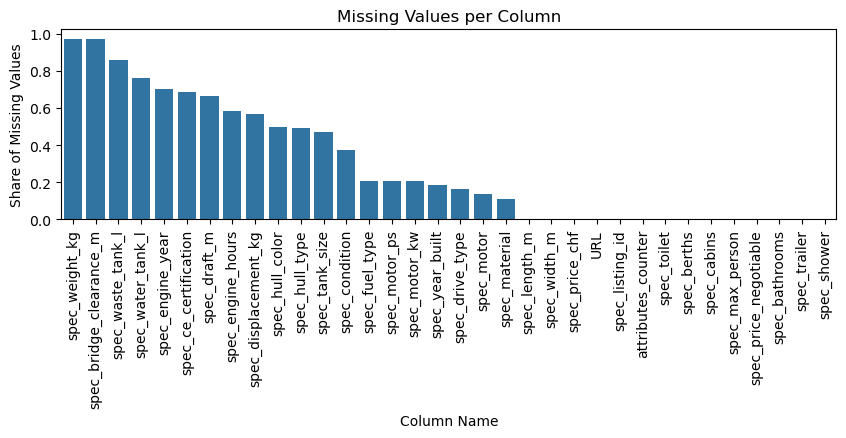

In [86]:
# See which columns have a lot of NA's and are not suitable as predictors
# Count missing values for each column
missing_counts = df_raw.isna().sum()

# Sort by number of missing values and calculate share from whole df
missing_counts = missing_counts.sort_values(ascending=False)
missing_share = missing_counts / len(df_raw)

# Plot counts of missing values per column
plt.figure(figsize=(10, 5))
sns.barplot(x=missing_share.index, y=missing_share.values)
plt.xticks(rotation=90)
plt.ylabel("Share of Missing Values")
plt.xlabel("Column Name")
plt.title("Missing Values per Column")
plt.subplots_adjust(bottom=0.5)
plt.show()


Looking at this plot I would suggest to make the cut at 'spec_fuel_type' and include all specs that have less NA's than this. It seems to be a good tradeoff between loosing some information (as we can't use these NA rows for regression) and having enough predictors. 

We can later try to impute some variables where we have existing variables.
To identify if we already 

In a first model we drop all columns that have more than 30% NA's for all other columns we impute NA's with the mean. Then we create two dataframes for later use, we 

After removing the columns with most missing values we either impute or drop the rows that still have missing values. We check for row completeness and decide for which rows we impute missing values (when a row has few NA's) and drop rows that have many missing values as imputation there would bias our model.

1325
1325


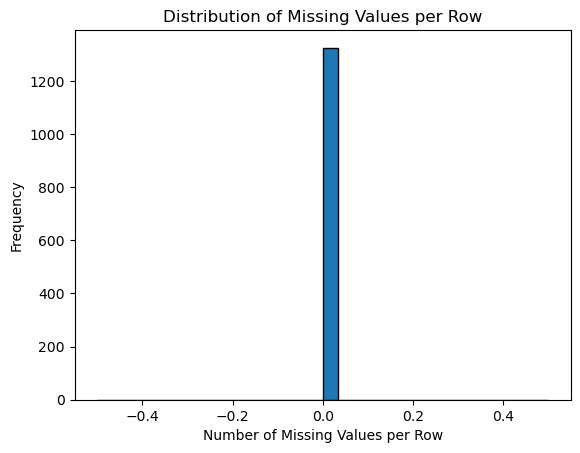

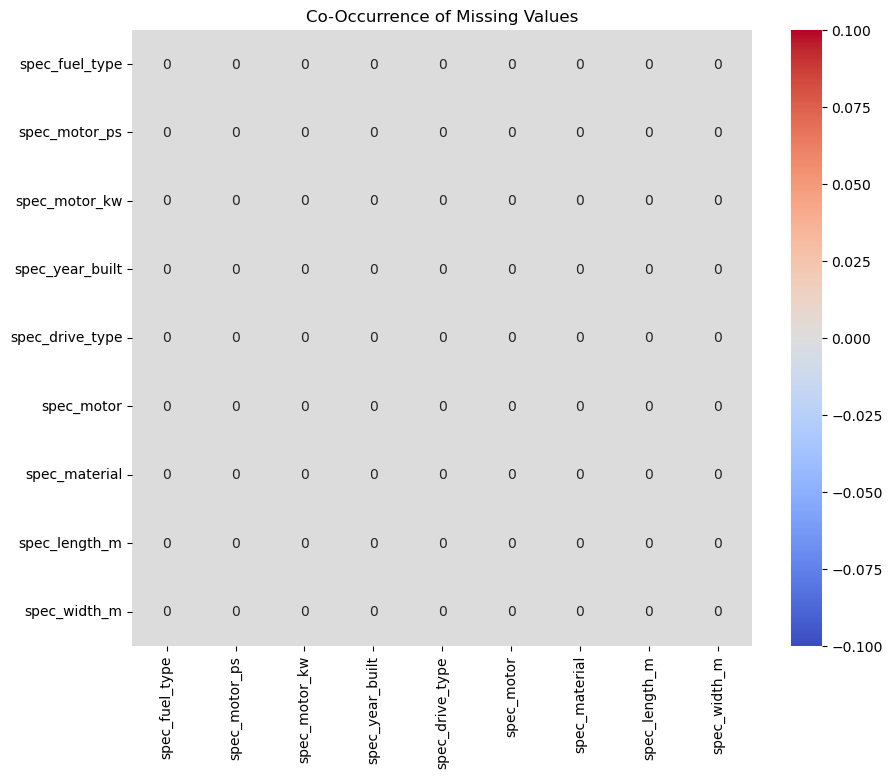

In [ ]:
# Exclude all columns with values shares bigger than 0.3
new_cols = missing_share[missing_share<=0.3].keys()
#print(new_cols)

# # subset df to only these columns and for the others drop all
df_clean = df_raw[new_cols].dropna()
print(len(df_clean))


# Count missing values per row
missing_per_row = df_clean.isna().sum(axis=1)

# Plot histogram of missing values per row to see the distribution
plt.hist(missing_per_row, bins=30, edgecolor='black')
plt.xlabel("Number of Missing Values per Row")
plt.ylabel("Frequency")
plt.title("Distribution of Missing Values per Row")
plt.show()

# # Motor NA's should be transformed to 'other'
# df_clean.loc[:,'spec_motor'] = df_clean['spec_motor'].fillna('other')
# #print(df['spec_motor'].value_counts(normalize=True))
# #print(df.select_dtypes(include=['float64']).columns.difference(['spec_listing_id', 'URL', 'spec_motor']))

# # Fill numerical columns with their median
# for col in df.select_dtypes(include=['float64', 'int64']).columns.difference(['spec_listing_id', 'URL', 'spec_motor', 'spec_price_chf']):
#     print(f'{col} filled {df[col].isna().sum()} NAs with median: {df[col].median()}')
#     df.loc[:,col] = df[col].fillna(df[col].median()).astype('float64')
#     #print(df[col].head())

# # Fill categorical columns with the most frequent value 
# for col in df.select_dtypes(include=[ 'string', 'object']).columns.difference(['spec_listing_id', 'URL', 'spec_motor', 'spec_price_chf']):
#     print(f'{col} filled {df.loc[:,col].isna().sum()} NAs with: {df.loc[:,col].mode()[0]}')
#     most_freq = df[col].mode()[0]
#     df.loc[:,col] = df[col].fillna(most_freq)

#print(df.columns)
cols_still_missing = missing_share[(missing_share > 0) & (missing_share <= 0.3)].keys()

# Create a binary missing value indicator matrix (1 if missing, 0 otherwise)
missing_matrix = df_clean[cols_still_missing].isna().astype(int)

# Compute co-occurrence matrix (dot product of missingness matrix)
co_occurrence = missing_matrix.T.dot(missing_matrix)

# Normalize by total missing count per column (optional, to get proportions)
#co_occurrence = co_occurrence.div(missing_matrix.sum(axis=0), axis=0)


# Plot Co-Occurence heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(co_occurrence, annot=True, cmap="coolwarm", fmt=".0f")
plt.title("Co-Occurrence of Missing Values")
plt.show()



Having now a complete dataset we want to fit a first model. We start by fitting an ordinary least square (OLS). To make sure the assumptions are met for such a model, we look at the distribution of the outcome price and transform with log if necessary.

/var/folders/dz/xk92rf811x11gfspml0l9cdr0000gn/T/ipykernel_3551/2284466391.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["log_spec_price_chf"] = np.log(df_clean["spec_price_chf"])


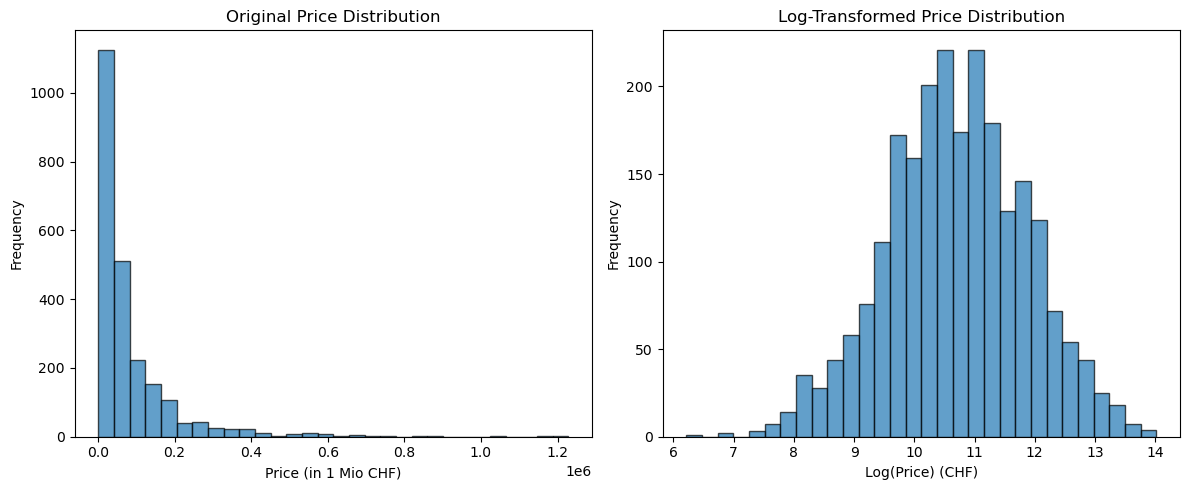

In [88]:
# Apply log transformation
df_clean["log_spec_price_chf"] = np.log(df_clean["spec_price_chf"])

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Original price distribution
axes[0].hist(df_clean["spec_price_chf"], bins=30, edgecolor="black", alpha=0.7)
axes[0].set_xlabel("Price (in 1 Mio CHF)")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Original Price Distribution")

# Log-transformed price distribution
axes[1].hist(df_clean["log_spec_price_chf"], bins=30, edgecolor="black", alpha=0.7)
axes[1].set_xlabel("Log(Price) (CHF)")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Log-Transformed Price Distribution")

# Adjust layout
plt.tight_layout()
plt.show()

Now we see that the log transformation of the outcome variable is necessary and we construct the first model with this. We first want to vizalize the data and see if there are any obvious relationships between price and the other variables.


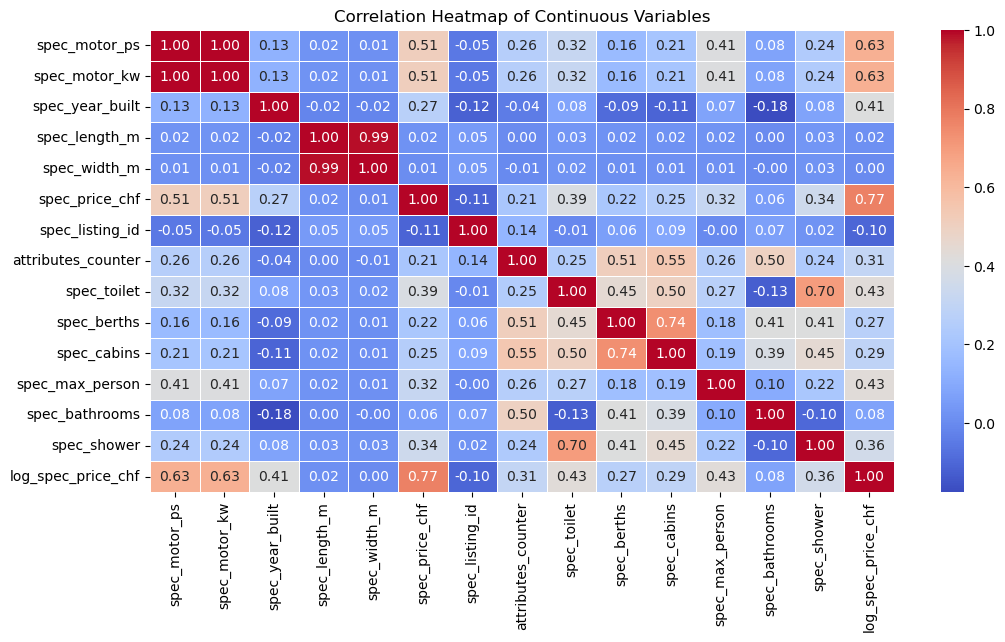

In [89]:
# Select only continuous variables
num_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns#.difference(['spec_listing_id', 'URL', 'spec_motor'])

# Compute correlation matrix
plt.figure(figsize=(12, 6))
sns.heatmap(df_clean[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap of Continuous Variables")
plt.show()



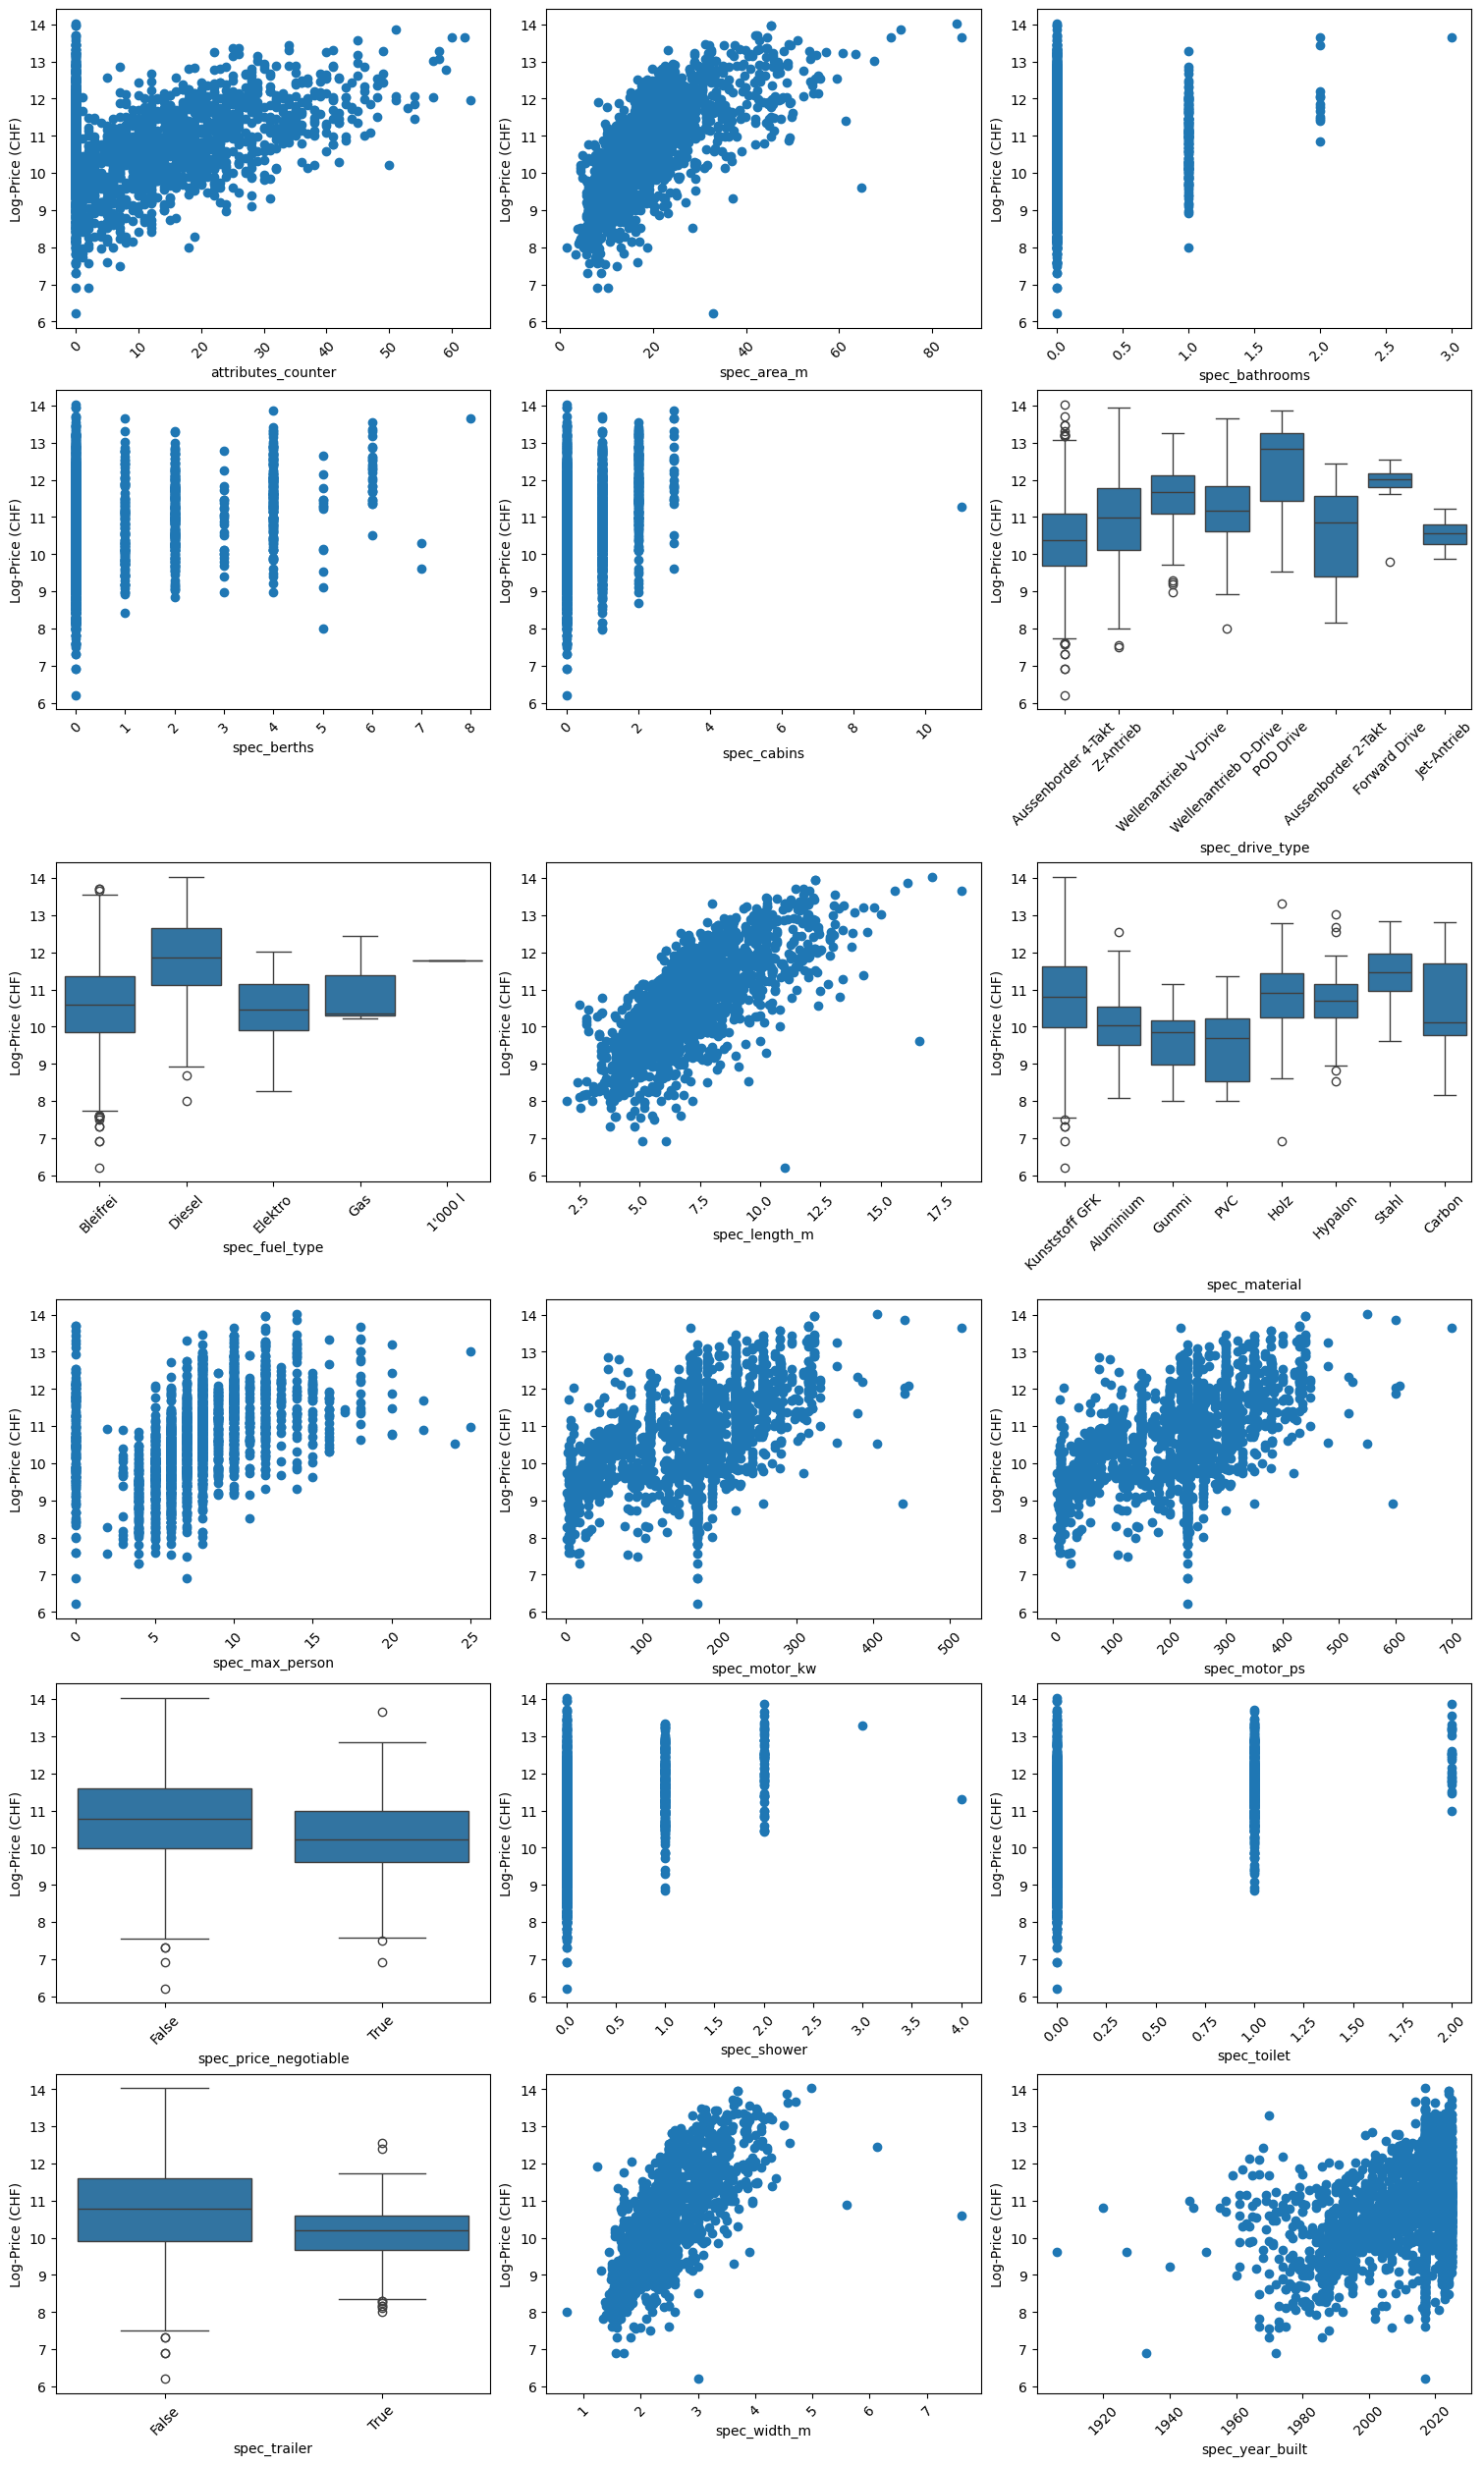

In [ ]:
# sns.pairplot(df, y_vars=["spec_price_chf"], x_vars=num_cols, height=2.5)
# plt.show()

# Select categorical variables (excluding ID and URL)
cat_cols = df_clean.select_dtypes(include=['string', 'object', 'bool']).columns.difference(['spec_listing_id', 'URL'])

# Set up the plot grid
n_plots = len(cat_cols) + len(num_cols)
fig, axes = plt.subplots(nrows=(n_plots // 3) + 1, ncols=3, figsize=(15, n_plots * 1.5), constrained_layout=True)

# Flatten axes array for easier iteration
axes = axes.flatten()

# Create boxplots for each categorical variable
for i, col in enumerate(df_clean.columns.difference(['spec_listing_id', 'URL', 'spec_motor', 'spec_price_chf', 'log_spec_price_chf'])):

    if df_clean[col].dtype in ['string', 'object', 'bool']:
        sns.boxplot(data=df_clean, x=col, y="log_spec_price_chf", ax=axes[i])
    elif df_clean[col].dtype in ['int64', 'float64']:
        axes[i].scatter( df_clean[col], df["log_spec_price_chf"])
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Log-Price (CHF)")
    axes[i].tick_params(axis='x', rotation=45)
        

# Remove unused subplots (if any)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.plot()
plt.show()

We already see quite some possible relationships between variables. We want to further inspect the variables 'width_m' and 'length_m' as they correlate perfectly we don't need to inlcude both in the model. I would suggest to introduce a variable called 'area_m' that takes the area. Furthermore we see some outliers in size, those seem to be very big boats, which can mess up the model easily. It also seems that including these boats that are way bigger into the analysis doesn't make sense, as their pricing also works very differently probably.

Also to increase the number in each group of Fuel type, we summarize all Bleifrei and all Diesel Type fuels. So we are only left with fuel types 'Diesel', 'Bleifrei' and 'Gas'.

   spec_area_m  spec_width_m  spec_length_m
0      12.4200          2.30           5.40
1      19.3548          2.54           7.62
2      18.6000          2.50           7.44
3      31.5000          3.00          10.50
4      23.7500          2.50           9.50
spec_fuel_type
Bleifrei    2085
Diesel       214
Elektro       17
Gas            3
1'000 l        1
Name: count, dtype: int64


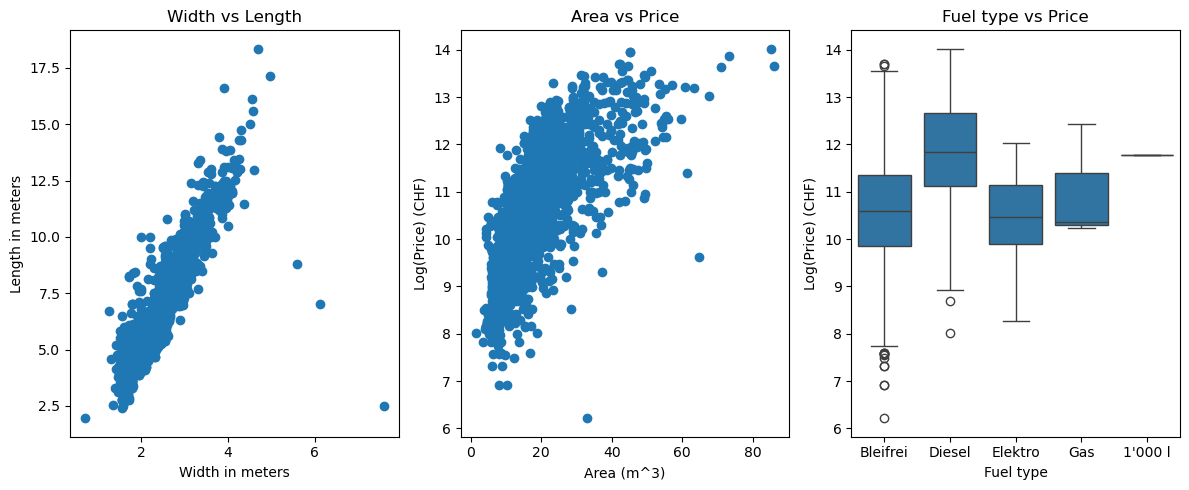

In [91]:
# Exclude outliers in size
df = df[df['spec_width_m'] < 150]
df['spec_area_m'] = df['spec_width_m'] * df['spec_length_m']
print(df[['spec_area_m', 'spec_width_m', 'spec_length_m']].head())

# Standardize 'Bleifrei' and 'Diesel' labels
df['spec_fuel_type'] = df['spec_fuel_type'].replace(
    to_replace={r".*Bleifrei.*": "Bleifrei", r".*Diesel.*": "Diesel"},
    regex=True
)
print(df['spec_fuel_type'].value_counts())

# Check Plots again
# Create side-by-side plots
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

# Length vs Width
axes[0].scatter(x=df['spec_width_m'], y=df['spec_length_m'])
axes[0].set_xlabel("Width in meters")
axes[0].set_ylabel("Length in meters")
axes[0].set_title("Width vs Length")

# Area vs Price
axes[1].scatter(x=df['spec_area_m'], y=df["log_spec_price_chf"])
axes[1].set_xlabel("Area (m^3)")
axes[1].set_ylabel("Log(Price) (CHF)")
axes[1].set_title("Area vs Price")

# Area vs Price
sns.boxplot(data=df, x='spec_fuel_type', y="log_spec_price_chf", ax=axes[2])
axes[2].set_xlabel("Fuel type")
axes[2].set_ylabel("Log(Price) (CHF)")
axes[2].set_title("Fuel type vs Price")

# Adjust layout
plt.tight_layout()
plt.show()

So, now its time to fit the first model. Simple first model with all available variables to see if there are any significant relationships.


In [92]:
from patsy import dmatrices
import statsmodels.api as sm

# Define variables to exclude
exclude_cols = ['URL', 'spec_listing_id', 'spec_width_m', 'spec_length_m', 'spec_price_chf', 'log_spec_price_chf', 'spec_motor']

# Construct the formula correctly
predictors = ' + '.join(df.columns.difference(exclude_cols))
formula = f'log_spec_price_chf ~ {predictors}'

print(f"Formula used: \n{formula}")

# Convert all string[python] columns to object
df = df.astype({col: "object" for col in df.select_dtypes(include="string").columns})

# Use dmatrices to form regression equation, the function creates the necessary matrices
y, X = dmatrices(formula, data=df, return_type='dataframe')

# print(y[:3])
# print(X[:3])

mod = sm.OLS(y, X)
res = mod.fit()
print(res.summary())

Formula used: 
log_spec_price_chf ~ attributes_counter + spec_area_m + spec_bathrooms + spec_berths + spec_cabins + spec_drive_type + spec_fuel_type + spec_material + spec_max_person + spec_motor_kw + spec_motor_ps + spec_price_negotiable + spec_shower + spec_toilet + spec_trailer + spec_year_built
                            OLS Regression Results                            
Dep. Variable:     log_spec_price_chf   R-squared:                       0.733
Model:                            OLS   Adj. R-squared:                  0.730
Method:                 Least Squares   F-statistic:                     202.9
Date:                Fri, 04 Apr 2025   Prob (F-statistic):               0.00
Time:                        10:08:25   Log-Likelihood:                -2113.0
No. Observations:                2320   AIC:                             4290.
Df Residuals:                    2288   BIC:                             4474.
Df Model:                          31                               

Now this model was made fit without the motor type, because there are so many different ones and we wanted to see the general effect of the other variables. Rigth now we have a very high r-aquared of 0.743 which seems very solid as predicting prices is our goal, we aim for a model with high r-squared and don't care so much about any p-values. In a next step we include the motor type again.

In [93]:
# Define variables to exclude
exclude_cols = ['URL', 'spec_listing_id', 'spec_width_m', 'spec_length_m', 'spec_price_chf', 'log_spec_price_chf']

# Construct the formula correctly
predictors = ' + '.join(df.columns.difference(exclude_cols))
formula = f'log_spec_price_chf ~ {predictors}'

print(f"Formula used: \n{formula}")

# Convert all string[python] columns to object
df = df.astype({col: "object" for col in df.select_dtypes(include="string").columns})

# Use dmatrices to form regression equation, the function creates the necessary matrices
y, X = dmatrices(formula, data=df, return_type='dataframe')

# print(y[:3])
# print(X[:3])

mod = sm.OLS(y, X)
res = mod.fit()
print(res.summary())

Formula used: 
log_spec_price_chf ~ attributes_counter + spec_area_m + spec_bathrooms + spec_berths + spec_cabins + spec_drive_type + spec_fuel_type + spec_material + spec_max_person + spec_motor + spec_motor_kw + spec_motor_ps + spec_price_negotiable + spec_shower + spec_toilet + spec_trailer + spec_year_built
                            OLS Regression Results                            
Dep. Variable:     log_spec_price_chf   R-squared:                       0.887
Model:                            OLS   Adj. R-squared:                  0.768
Method:                 Least Squares   F-statistic:                     7.461
Date:                Fri, 04 Apr 2025   Prob (F-statistic):          1.18e-219
Time:                        10:08:27   Log-Likelihood:                -1116.5
No. Observations:                2320   AIC:                             4613.
Df Residuals:                    1130   BIC:                         1.145e+04
Df Model:                        1189                  

We start making predictions using the sklearn library, where we can also easily perform crossvalidations.

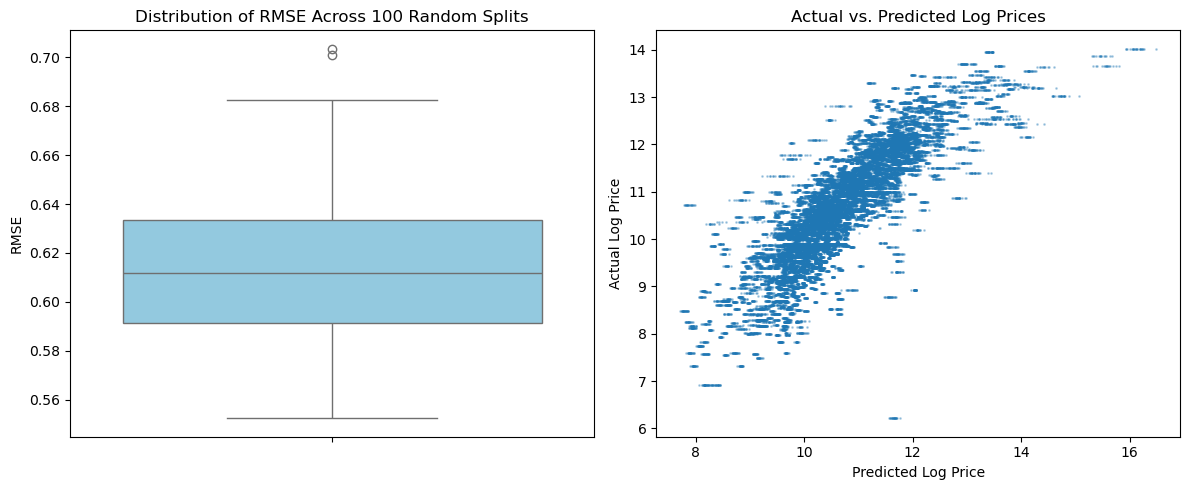

Average deviation of price prediction is 0.85 CHF


In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Define number of iterations
num_iterations = 100
rmse_values = []
y_preds, y_tests = [], []

# Define variables to exclude
exclude_cols = ['URL', 'spec_listing_id', 'spec_width_m', 'spec_length_m', 'spec_price_chf', 'spec_motor']
df_lm = df.drop(columns=exclude_cols)

# Select categorical column BEFORE encoding (for stratification)
stratify_col = 'spec_drive_type' if 'spec_drive_type' in df.columns else 'spec_material'

# Convert string columns to objects
df_lm = df_lm.astype({col: "object" for col in df_lm.select_dtypes(include="string").columns})

# One-hot encode categorical variables
df_lm = pd.get_dummies(df_lm, columns=df_lm.select_dtypes(include="object").columns, drop_first=True)

# Run cross-validation
for _ in range(num_iterations):
    # Ensure the stratify column exists in original df, not one-hot encoded df_lm
    if stratify_col in df.columns and df[stratify_col].nunique() > 1:
        strat_split = StratifiedShuffleSplit(n_splits=1, test_size=0.2)
        for train_idx, test_idx in strat_split.split(df, df[stratify_col]):
            df_train, df_test = df_lm.iloc[train_idx], df_lm.iloc[test_idx]
    else:
        df_train, df_test = train_test_split(df_lm, test_size=0.2)

    # Align train and test columns to avoid missing features
    df_train, df_test = df_train.align(df_test, join="left", axis=1, fill_value=0)
    
    # Split dataset into features (X) and target (y)
    X_train = df_train.drop(columns=['log_spec_price_chf'])
    y_train = df_train['log_spec_price_chf']
    X_test = df_test.drop(columns=['log_spec_price_chf'])
    y_test = df_test['log_spec_price_chf']

    # Train model
    lm = LinearRegression()
    lm.fit(X_train, y_train)

    # Predict on test set
    y_pred = lm.predict(X_test)
    
    # Store RMSE and predictions
    rmse_values.append(np.sqrt(mean_squared_error(y_test, y_pred)))
    y_preds.extend(y_pred)
    y_tests.extend(y_test)

# Convert results to DataFrame
rmse_df = pd.DataFrame({"RMSE": rmse_values})

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot of RMSE
sns.boxplot(y=rmse_df["RMSE"], color="skyblue", ax=axes[0])
axes[0].set_title(f"Distribution of RMSE Across {num_iterations} Random Splits")
axes[0].set_ylabel("RMSE")

# Scatter plot of predicted vs actual values
axes[1].scatter(x=y_preds, y=y_tests, alpha=0.3, s=1)
axes[1].set_xlabel("Predicted Log Price")
axes[1].set_ylabel("Actual Log Price")
axes[1].set_title("Actual vs. Predicted Log Prices")


# Adjust layout
plt.tight_layout()
plt.show()

# Calculate and print mean deviation in price (converted back from log)
mean_dev = round(np.expm1(np.mean(rmse_df['RMSE'])), 2)
print(f'Average deviation of price prediction is {mean_dev} CHF')


Now we want to look at a model that also takes motortypes into consideration again. This time we unfortunately can't perform a cross validation, as there are to many motortypes and some are only available once or twice in the dataset.


Index(['spec_fuel_type', 'spec_motor_ps', 'spec_motor_kw', 'spec_year_built',
       'spec_drive_type', 'spec_motor', 'spec_material', 'spec_length_m',
       'spec_width_m', 'spec_price_chf', 'URL', 'spec_listing_id',
       'attributes_counter', 'spec_toilet', 'spec_berths', 'spec_cabins',
       'spec_max_person', 'spec_price_negotiable', 'spec_bathrooms',
       'spec_trailer', 'spec_shower', 'log_spec_price_chf', 'spec_area_m'],
      dtype='object')
2320
2320
0       1582
1       1090
2       1982
3         25
4       2086
        ... 
2324     993
2325      59
2326     487
2327     525
2328    1938
Name: log_spec_price_chf, Length: 2320, dtype: int64
2320
2320


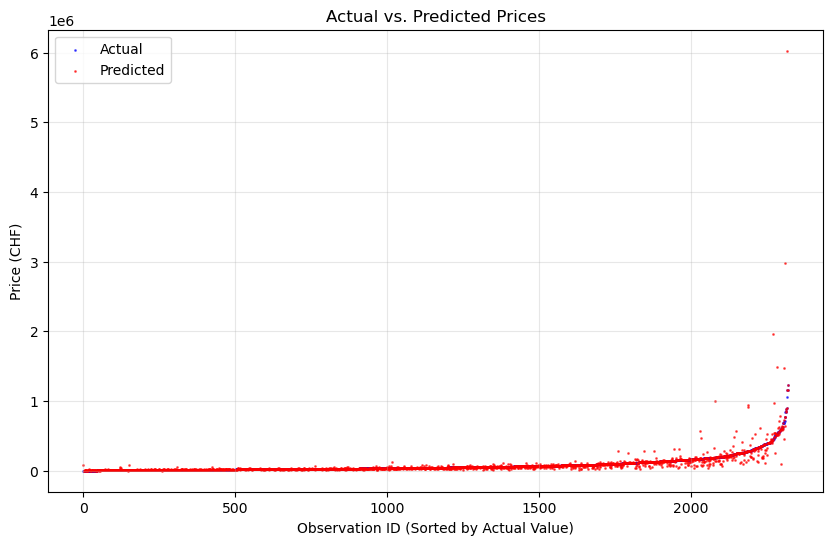

The average price prediction with our model is 126768.54969666328 higher than 


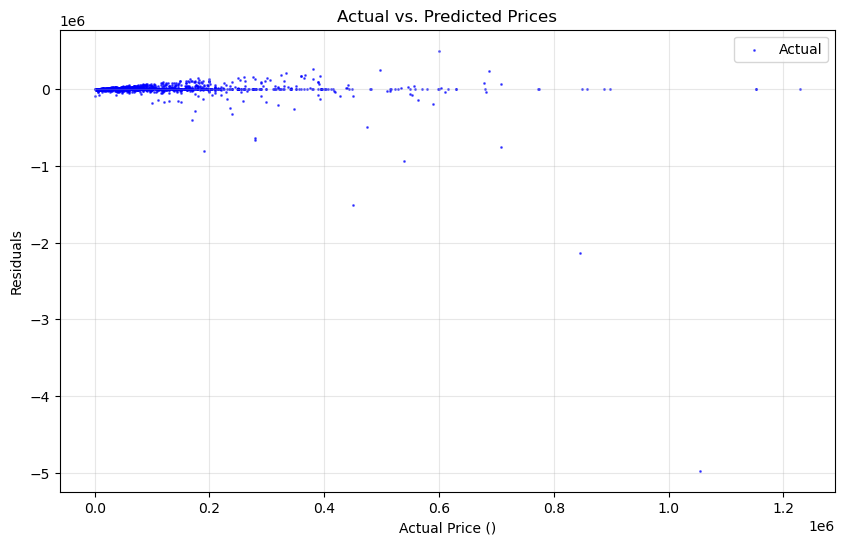

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

print(df.columns)
# Define variables to exclude
exclude_cols = ['URL', 'spec_listing_id', 'spec_width_m', 'spec_length_m', 'spec_price_chf']
df_fit = df.drop(columns=exclude_cols)

# Convert all string columns to object type (for encoding)
df_fit = df_fit.astype({col: "object" for col in df_fit.select_dtypes(include="string").columns})

# One-hot encode categorical variables
df_fit = pd.get_dummies(df_fit, columns=df_fit.select_dtypes(include="object").columns, drop_first=True)

# Define Features (X) and Target (y)
X = df_fit.drop(columns=['log_spec_price_chf'])
y = df_fit['log_spec_price_chf']

#print(X.columns)

# Split data into train and test sets (80% train, 20% test)
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model only on training data
lm = LinearRegression()
lm.fit(X, y)

# Predict on test data
y_pred = lm.predict(X)

# Convert back from log prices to original price scale
y_actual_exp = np.exp(df_fit['log_spec_price_chf'])
y_pred_exp = np.exp(y_pred)
# y_actual_exp = df_fit['log_spec_price_chf']
# y_pred_exp = y_pred
print(len(y_actual_exp))
print(len(y_pred_exp))

# Sort by actual values before assigning IDs
sorted_indices = np.argsort(y_actual_exp)

print(sorted_indices)

y_actual_sorted = y_actual_exp.iloc[sorted_indices].values
y_pred_sorted = y_pred_exp[sorted_indices]
print(len(y_actual_sorted))
print(len(y_pred_sorted))
# Assign an ID to each observation (sorted)
observation_ids = np.arange(1, len(y_actual_sorted) + 1)

# Plot actual vs. predicted values
plt.figure(figsize=(10, 6))
plt.scatter(observation_ids, y_actual_sorted, color="blue", label="Actual", alpha=0.6, s=1)
plt.scatter(observation_ids, y_pred_sorted, color="red", label="Predicted", alpha=0.6, s=1)
plt.xlabel("Observation ID (Sorted by Actual Value)")
plt.ylabel("Price (CHF)")
plt.title("Actual vs. Predicted Prices")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Calculate and print mean deviation in price (converted back from log)
rmse = np.sqrt(mean_squared_error(y_actual_sorted, y_pred_sorted))
print(f'The average price prediction with our model is {rmse} higher than ')



# Plot residuals vs outcome
residuals = y_actual_sorted - y_pred_sorted

# Plot actual vs. predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_actual_sorted, residuals,color="blue", label="Actual", alpha=0.6, s=1)
plt.xlabel("Actual Price ()")
plt.ylabel("Residuals")
plt.title("Actual vs. Predicted Prices")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


